In [1]:
# python libraries imports
import pandas as pd
import numpy as np

# customed local functions imports
import sys
sys.path.append("./scripts")

from rankings import *
from prep_data import *
from metrics import *
from attacks import *

#### **Dataset load and details**

In [2]:
ratings = load_ml1m()
print("============= MovieLens 1M Dataset ============")
print(f"#Ratings: {ratings["rating"].count()} | #Users: {ratings['user'].nunique()} | #Items: {ratings['item'].nunique()} ")

============= MovieLens 1M Dataset ============
#Ratings: 1000209 | #Users: 6040 | #Items: 3706 


#### **Split dataset across sellers**
*Algorthm 2 (Ramos et al 2025)*. randomly assign set of sellers to items; randomly assign ratings to sellers


In [3]:
split_ratings = {}

for i in [4, 5, 6, 7]:
    split_ratings[i] = split_ds_sellers(ratings, i)

    print(f"================ #{i} SELLERS ================")

    avg_users = split_ratings[i].groupby("seller")["user"].nunique().mean()
    avg_items = split_ratings[i].groupby("seller")["item"].nunique().mean()
    avg_ratings = split_ratings[i].groupby("seller")["rating"].count().mean()

    print(f"Avg. number of users per seller: {avg_users:.2f}\n"
            f"Avg. number of items per seller: {avg_items:.2f}\n"
            f"Avg. number of ratings per seller: {avg_ratings:.2f}")

================ #4 SELLERS ================
Avg. number of users per seller: 6038.00
Avg. number of items per seller: 2210.00
Avg. number of ratings per seller: 250052.25
================ #5 SELLERS ================
Avg. number of users per seller: 6037.00
Avg. number of items per seller: 2126.20
Avg. number of ratings per seller: 200041.80
================ #6 SELLERS ================
Avg. number of users per seller: 6028.67
Avg. number of items per seller: 2045.00
Avg. number of ratings per seller: 166701.50
================ #7 SELLERS ================
Avg. number of users per seller: 6017.86
Avg. number of items per seller: 1961.00
Avg. number of ratings per seller: 142887.00


#### **Exp. results - Ranking Effectiveness**
*Kendall Tau*

In [ ]:
# ranking the marketplace could have created in case all the plain ratings of all sellers 
# would have been directly available to it in a nonfederated setting (eq. 3)
baseline_rank = reputation_ranking(ratings, lamb=.1)

algorithms = {"n_aa": n_aa, "w_aa": w_aa, "fed_rep": federated_reputation_ranking}
kendall_res=[]
for i in [4,5,6,7]:
    for name, rank_algo in algorithms.items():
        rank = rank_algo(split_ratings[i])
        kendall = kendall_tau(baseline_rank, rank)

        kendall_res.append({"Num Sellers": i,
                            "Algorithm": name,
                            "kendall tau": kendall})

kendall_res = pd.DataFrame(kendall_res)
display(kendall_res)


,Num Sellers,Algorithm,kendall tau
0,4,n_aa,0.970853
1,4,w_aa,0.998515
2,4,fed_rep,0.997970
3,5,n_aa,0.968071
4,5,w_aa,0.998536
5,5,fed_rep,0.997943
6,6,n_aa,0.965035
7,6,w_aa,0.998580
8,6,fed_rep,0.997780
9,7,n_aa,0.962202


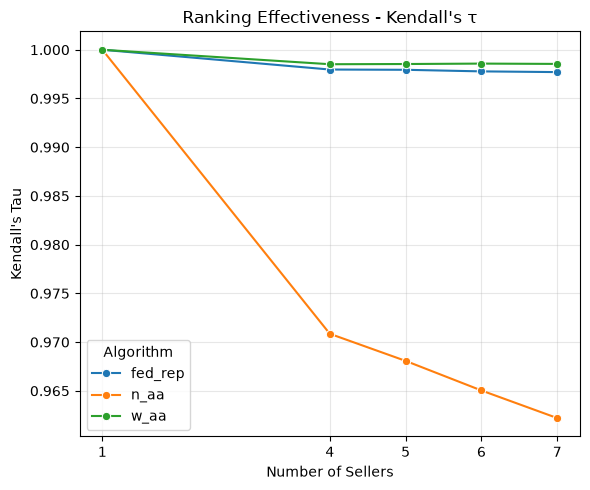

In [5]:
plot_kendall(kendall_res)

#### **Exp. Results - Sellers' Satisfaction**
*MAE*

In [6]:
mae_res=[]
for i in [4,5,6,7]:
    for name, rank_algo in algorithms.items():
        rank = rank_algo((split_ratings[i]))
        mae = mean_abs_error(split_ratings[i], rank)

        mae_res.append({"Num Sellers": i,
                            "Algorithm": name,
                            "MAE": mae})

mae_res = pd.DataFrame(mae_res)
display(mae_res)

,Num Sellers,Algorithm,MAE
0,4,n_aa,0.028002
1,4,w_aa,0.027962
2,4,fed_rep,0.027933
3,5,n_aa,0.031247
4,5,w_aa,0.031225
5,5,fed_rep,0.031195
6,6,n_aa,0.034818
7,6,w_aa,0.034907
8,6,fed_rep,0.034869
9,7,n_aa,0.037611


#### **Experimental Results - Robustness**
*Kendal Tau - push-nuke attack*. A seller pushes the ranking of  an item to the maximum value, and nukes a randomly selected set of 10 other items

In [4]:
# Ranking the marketplace could have created in case all the plain ratings 
# of all sellers would have been directly available to it in a non-federated setting (eq. 3)
baseline_rank = reputation_ranking(ratings, lamb=.1)

algorithms = {"n_aa": n_aa, "w_aa": w_aa, "fed_rep": federated_reputation_ranking}

kendall_res = []

for i in [4, 5, 6, 7]:

    # Original rankings without attack
    original = split_ratings[i]

    # Generate attacked dataset
    attacked = push_nuke(original)

    for name, rank_algo in algorithms.items():

        # Compute original and attacked rankings
        original_rank = rank_algo(original)
        attacked_rank = rank_algo(attacked)

        # Compare rankings
        kendall = kendall_tau(original_rank, attacked_rank)

        kendall_res.append({
            "Num Sellers": i,
            "Algorithm": name,
            "kendall tau": kendall
        })

kendall_res = pd.DataFrame(kendall_res)
display(kendall_res)

,Num Sellers,Algorithm,kendall tau
0,4,n_aa,0.997187
1,4,w_aa,0.997110
2,4,fed_rep,0.997163
3,5,n_aa,0.996451
4,5,w_aa,0.996528
5,5,fed_rep,0.996673
6,6,n_aa,0.996899
7,6,w_aa,0.996644
8,6,fed_rep,0.996771
9,7,n_aa,0.997392


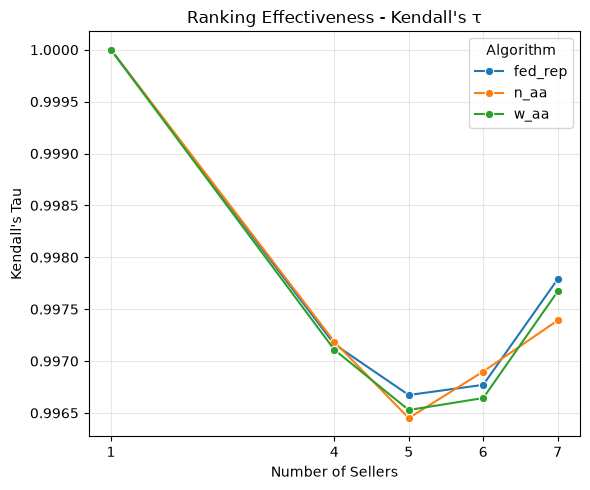

In [5]:
plot_kendall(kendall_res)